# Demanda eléctrica en España (2023-2026)
### Prueba técnica individual · Career Tech Hub · Sesión 03

**Autora:** Paola Tron Escobosa
**Fecha:** noviembre de 2026
**Herramientas:** Python (pandas), SQL (SQLite) y Excel

**Datos:** demanda diaria, generación por tecnología y tiempo, del 01/01/2023 al 15/11/2026 (2026 incompleto).

**Resultados principales**
- **115 días** superaron los 800 GWh de demanda, 64 de ellos solo en 2026 (año aún incompleto).
- Los días de descanso se demanda en torno a un **14 % menos** que los laborables, de forma estable todos los años.
- La demanda sube tanto con el **frío** como con el **calor**: los meses de menor consumo son los templados (abril y octubre).

**Contenido:** Parte A (pandas) · Parte B (SQL y reto con LAG) · Parte C (Excel) · Parte D (explicación y uso de IA)

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Las hojas del Excel (para la parte A)
dias = pd.read_excel("../data/electricidad_para_panel.xlsx", sheet_name="dias")
generacion = pd.read_excel("../data/electricidad_para_panel.xlsx", sheet_name="generacion")

# La base de datos (para la parte B)
conexion = sqlite3.connect("../data/electricidad.db")

def sql(consulta):
    # Lanza una consulta y devuelve el resultado como tabla de pandas.
    return pd.read_sql(consulta, conexion)

print("Hoja dias:", dias.shape[0], "filas ·", list(dias.columns))
sql("SELECT type AS tipo, name AS nombre FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

Hoja dias: 1415 filas · ['fecha', 'dia_semana', 'mes', 'festivo', 'descanso', 't_med', 'demanda_gwh', 'año']


,tipo,nombre
0,table,ciudades
1,table,demanda
2,table,festivos
3,table,generacion
4,table,predicciones
5,table,tiempo
6,view,tabla_dias
7,view,temperatura_nacional


Columnas de las tablas de la base de datos:

| Tabla | Columnas |
|---|---|
| `demanda` | `fecha`, `demanda_gwh` |
| `generacion` | `fecha`, `tecnologia`, `tipo`, `gwh` |
| `tiempo` | `fecha`, `ciudad`, `t_max`, `t_min`, `t_med`, `lluvia_mm`, `viento_kmh`, `sol_mj` |
| `ciudades` | `ciudad`, `latitud`, `longitud`, `habitantes` |
| `festivos` | `fecha`, `festivo` |
| `temperatura_nacional` (vista) | `fecha`, `t_med` |
| `tabla_dias` (vista) | `fecha`, `demanda_gwh`, `t_med`, `festivo`, `demanda_ayer`, `demanda_hace_7` |

# Parte A · pandas


**Exploración inicial**

Si bien la tabla `dias` se encuentra preparada para la presente prueba técnica, resulta necesario revisar su estructura (columnas, tipos de datos, nulos y duplicados) para poder responder a las preguntas correctamente, por lo que se realiza una breve exploración inicial. 

In [2]:
dias

,fecha,dia_semana,mes,festivo,descanso,t_med,demanda_gwh,año
0,2023-01-01,domingo,1,1,True,10.24,506.425906,2023
1,2023-01-02,lunes,1,0,False,10.25,621.645824,2023
2,2023-01-03,martes,1,0,False,9.20,677.052137,2023
3,2023-01-04,miércoles,1,0,False,7.79,689.160950,2023
4,2023-01-05,jueves,1,0,False,7.32,671.291045,2023
...,...,...,...,...,...,...,...,...
1410,2026-11-11,miércoles,11,0,False,16.12,688.687550,2026
1411,2026-11-12,jueves,11,0,False,16.39,698.606940,2026
1412,2026-11-13,viernes,11,0,False,15.05,707.449750,2026
1413,2026-11-14,sábado,11,0,True,14.13,615.539670,2026


In [3]:
#Periodo comprendido
inicio = dias["fecha"].min().strftime("%d/%m/%Y")

fin = dias["fecha"].max().strftime("%d/%m/%Y")

print("Los datos abarcan el siguiente periodo de tiempo: \n")

print("Fecha inicial: ", inicio)
print("Fecha final: ", fin)

Los datos abarcan el siguiente periodo de tiempo: 

Fecha inicial:  01/01/2023
Fecha final:  15/11/2026


Los datos van del 01/01/2023 al 15/11/2026, así que 2026 no está completo: falta la segunda quincena de noviembre y todo diciembre. Hay que tenerlo en cuenta al hacer comparaciones con los años anteriores.

In [4]:
dias.info()

<class 'pandas.DataFrame'>
RangeIndex: 1415 entries, 0 to 1414
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   fecha        1415 non-null   datetime64[us]
 1   dia_semana   1415 non-null   str           
 2   mes          1415 non-null   int64         
 3   festivo      1415 non-null   int64         
 4   descanso     1415 non-null   bool          
 5   t_med        1415 non-null   float64       
 6   demanda_gwh  1415 non-null   float64       
 7   año          1415 non-null   int64         
dtypes: bool(1), datetime64[us](1), float64(2), int64(3), str(1)
memory usage: 88.4 KB


La tabla `dias` tiene un total de 8 columnas y 1415 filas (una por día): 

* No hay valores nulos. 
* Los tipos de datos son coherentes con el tipo de variable, siendo estos:
  - datetime64 para fecha.
  - str para el nombre de los días.
  - int64 para mes y año
  - int64 para festivo,clasificados como 1 (festivo)/ 0 (no festivo).
  - float64 para temperatura media y demanda de energía.
  - bool para descanso (True/False).

In [5]:
# Se determina si hay filas duplicadas
dias.duplicated().sum()

np.int64(0)

In [6]:
#Se determina si hay fechas duplicadas
dias["fecha"].duplicated().sum()

np.int64(0)

Se observa que no hay filas duplicadas ni fechas repetidas (cada fila corresponde a un único día).

**Respuestas del punto A**

**A1.** ¿Cuántos días superaron los 800 GWh de demanda? ¿Cuántos fueron en cada año?

In [7]:
# Para determinar la cantidad de días con una demanda mayor a 800GWh, se debe:

# Seleccionar los días en los que la demanda supera los 800GWh:
d_800GWh = dias[dias["demanda_gwh"]> 800]

# Contar los registros encontrados, los cuales corresponden al periodo completo: 
cuenta_d800GWh = len(d_800GWh)

print(f"El número total de días con demanda superior a 800GWh para el periodo contemplado entre el {inicio} y el {fin} fue:", cuenta_d800GWh)

El número total de días con demanda superior a 800GWh para el periodo contemplado entre el 01/01/2023 y el 15/11/2026 fue: 115


In [8]:
#Para determinar la cantidad de días por año se debe agrupar por año y contar:
conteo = d_800GWh.groupby("año").size()

Entre el 01/01/2023 y el 15/11/2026, 115 días superaron los 800 GWh: 16 en 2023, 10 en 2024, 25 en 2025 y 64 en 2026. Salvo el descenso de 2024, la cifra aumenta, y destaca 2026, que, aunque no está completo, ya supera el doble que el año anterior. Esto podría deberse a varios factores, como más calor o más consumo eléctrico (ver mapa de calor en la A3: 2026 tuvo meses más extremos).

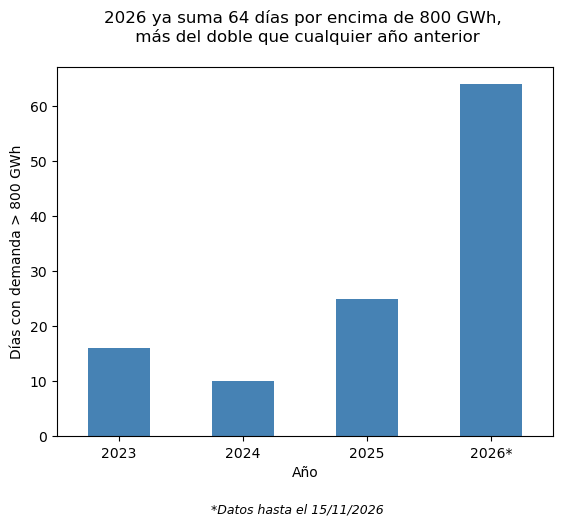

In [9]:
#Gráfico de barras

ax = conteo.plot(kind="bar", color="steelblue")
ax.set_title("2026 ya suma 64 días por encima de 800 GWh, \n más del doble que cualquier año anterior\n")
ax.set_xlabel("Año")
ax.set_ylabel("Días con demanda > 800 GWh")

# 1. Cambiar la etiqueta de 2026 por "2026*"
etiquetas = [f"{a}*" if a == 2026 else str(a) for a in conteo.index]
ax.set_xticklabels(etiquetas, rotation=0)

# 2. Añadir la nota debajo del gráfico
plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026",
            ha="center", fontsize=9, style="italic")

plt.show()

In [10]:
# Se plantea la consulta SQL. Días de la semana con demanda superior a 800 GWh por año
sql_800_dia = """
SELECT strftime('%Y', fecha) AS año,
       strftime('%w', fecha) AS num_dia,
	   CASE strftime('%w', fecha)
            WHEN '0' THEN 'Domingo'
            WHEN '1' THEN 'Lunes'
            WHEN '2' THEN 'Martes'
            WHEN '3' THEN 'Miércoles'
            WHEN '4' THEN 'Jueves'
            WHEN '5' THEN 'Viernes'
            WHEN '6' THEN 'Sábado'
       END AS dia_semana,
       COUNT(*) AS dias_800
FROM demanda
WHERE demanda_gwh > 800
GROUP BY año, num_dia
ORDER BY año, num_dia;
"""

#Se construye el df:
df_800_dia = pd.read_sql(sql_800_dia, conexion)
df_800_dia

,año,num_dia,dia_semana,dias_800
0,2023,2,Martes,5
1,2023,3,Miércoles,6
2,2023,4,Jueves,3
3,2023,5,Viernes,2
4,2024,2,Martes,2
5,2024,3,Miércoles,4
6,2024,4,Jueves,3
7,2024,5,Viernes,1
8,2025,1,Lunes,3
9,2025,2,Martes,5


La demanda de energía eléctrica que supera los 800 GWh corresponde a los días de semana (laborables).

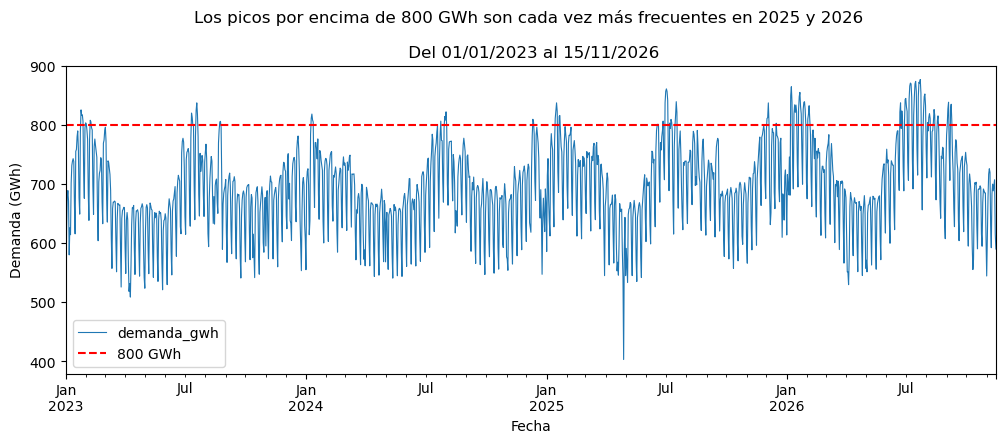

In [11]:
#Demanda diaria

ax = dias.plot(x="fecha", y="demanda_gwh", figsize=(12, 4), legend=False, linewidth=0.8)
ax.axhline(800, color="red", linestyle="--", label="800 GWh")
ax.set_title("Los picos por encima de 800 GWh son cada vez más frecuentes en 2025 y 2026 \n \n Del 01/01/2023 al 15/11/2026")
ax.set_ylabel("Demanda (GWh)")
ax.set_xlabel("Fecha")
ax.legend()
plt.show()

Todos los días por encima de 800 GWh son laborables (según la consulta por día de la semana) y se concentran sobre todo en julio y agosto, por el aire acondicionado, y en enero y febrero, por la calefacción. Estos picos son cada vez más frecuentes, y 2026 es el año con más, aunque aún no ha terminado. El descenso más marcado de la serie es el del 28/04/2025 (403 GWh), que coincide con el apagón. 


**A2.** Haz una tabla con la demanda media de cada año, separando los días laborables de los días de descanso (columna `descanso`). ¿Qué porcentaje menos se gasta en un día de descanso, cada año?

In [12]:
# Para realizar la tabla es necesario agrupar por año y descanso. Se generan 3 columnas donde la primera corresponde al año, y las dos restantes a
# corresponden a False (días laborables) y True (descanso)

df_dMedia = dias.groupby(["año","descanso"])["demanda_gwh"].mean().round(2).unstack()
df_dMedia


descanso,False,True
año,,
2023,707.72,605.50
2024,710.06,612.02
2025,732.49,633.23
2026,749.86,643.03


In [13]:
#Para saber qué porcentaje menos se gasta en un día de descanso respecto a un día laborable de debe calcular:
# (laborable - descanso) / laborable * 100
#True = descanso y False = Laborable, como se mencionó anteriormente.

df_dMedia["% menos en descanso"] = (df_dMedia[False] - df_dMedia[True])/df_dMedia[False]*100
df_dMedia.round(2)

descanso,False,True,% menos en descanso
año,,,
2023,707.72,605.50,14.44
2024,710.06,612.02,13.81
2025,732.49,633.23,13.55
2026,749.86,643.03,14.25


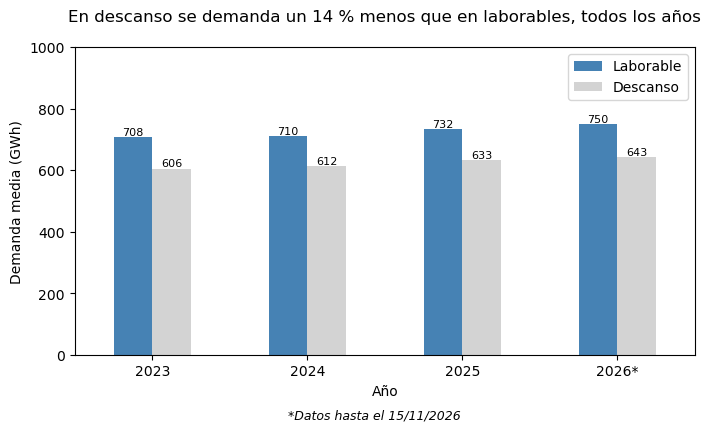

In [14]:
datos = df_dMedia.drop(columns="% menos en descanso").copy()
datos.columns = ["Laborable", "Descanso"]
datos.index = [f"{a}*" if a == 2026 else str(a) for a in datos.index]

ax = datos.plot(kind="bar", rot=0, color=["steelblue", "lightgray"], figsize=(8, 4))
ax.set_title("En descanso se demanda un 14 % menos que en laborables, todos los años\n")
ax.set_xlabel("Año")
ax.set_ylabel("Demanda media (GWh)")
ax.set_ylim(0, 1000)
ax.legend(title="")

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", fontsize=8)

plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026",
            ha="center", fontsize=9, style="italic")
plt.show()

En días de descanso se demanda aproximadamente entre un 13,5% y un 14,5% menos de electricidad por año que en días laborables. Esto podría deberse a que en esos días las actividades económicas como la industria y los servicios disminuyen.

**A3.** ¿Cuál fue el mes con mayor demanda media de los cuatro años (di el mes y el año)? ¿Y el de menor?

In [15]:
# Se calcula la demanda media agrupada por mes y año, para los 4 años:
df_dMes = dias.groupby(["año","mes"])["demanda_gwh"].mean().round(2)


In [16]:
#El mes y el año con el mayor valor son:
año_max, mes_max = df_dMes.idxmax()
# El valor máximo demandado es:
dem_max= df_dMes.max()

print(f"La mayor demanda media de energía eléctrica contemplada hasta la fecha {fin} corresponde al {mes_max}/{año_max} con un valor de {dem_max} GWh")

La mayor demanda media de energía eléctrica contemplada hasta la fecha 15/11/2026 corresponde al 7/2026 con un valor de 814.83 GWh


In [17]:
#El mes y el año con el menor valor son:
año_min, mes_min = df_dMes.idxmin()
# El valor mínimo demandado es:
dem_min= df_dMes.min()

print(f"La menor demanda media de energía eléctrica contemplada hasta la fecha {fin} corresponde al {mes_min}/{año_min} con un valor de {dem_min} GWh")

La menor demanda media de energía eléctrica contemplada hasta la fecha 15/11/2026 corresponde al 4/2023 con un valor de 610.56 GWh


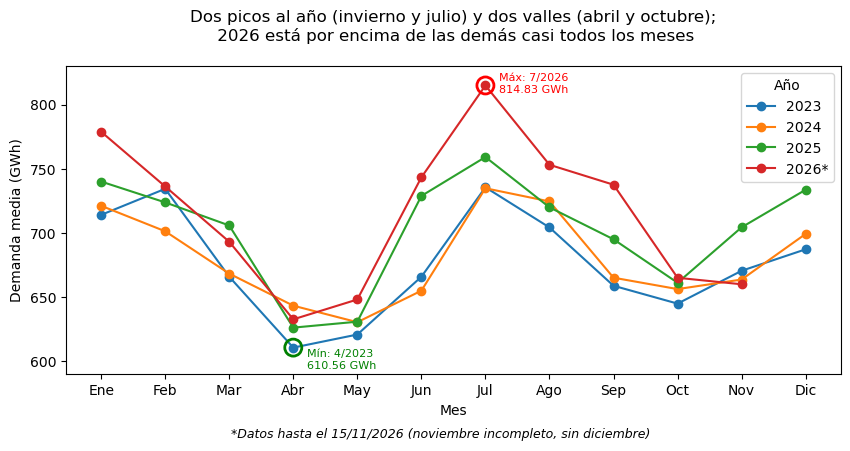

In [18]:
# Meses en filas, años en columnas
tabla_mes = df_dMes.unstack(level="año")
tabla_mes.columns = [f"{a}*" if a == 2026 else str(a) for a in tabla_mes.columns]

ax = tabla_mes.plot(marker="o", figsize=(10, 4))

# Marcar el máximo y el mínimo
ax.scatter(mes_max, dem_max, s=150, facecolors="none", edgecolors="red", linewidths=2, zorder=5)
ax.annotate(f"Máx: {mes_max}/{año_max}\n{dem_max} GWh", (mes_max, dem_max),
            textcoords="offset points", xytext=(10, -5), fontsize=8, color="red")

ax.scatter(mes_min, dem_min, s=150, facecolors="none", edgecolors="green", linewidths=2, zorder=5)
ax.annotate(f"Mín: {mes_min}/{año_min}\n{dem_min} GWh", (mes_min, dem_min),
            textcoords="offset points", xytext=(10, -15), fontsize=8, color="green")
ax.set_ylim(590, 830)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("Dos picos al año (invierno y julio) y dos valles (abril y octubre);\n 2026 está por encima de las demás casi todos los meses\n")
ax.set_xlabel("Mes")
ax.set_ylabel("Demanda media (GWh)")
ax.legend(title="Año")

plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026 (noviembre incompleto, sin diciembre)",
            ha="center", fontsize=9, style="italic")
plt.show()

La demanda tiene dos picos al año, en diciembre-enero y en julio, por el uso de calefacción y aire acondicionado, y dos valles, en abril y octubre, cuando el clima es más templado. La demanda de 2025 y, sobre todo, la de 2026 están por encima de las de 2023 y 2024, que presentan valores similares. Noviembre de 2026 queda por debajo de noviembre de 2025 porque solo incluye la primera quincena, por lo que debe descartarse al comparar.

In [19]:
#Se plantea consulta SQL para saber cuál es la temperatura asociada a los picos y los valles:
sql_dem_mensual = """
    SELECT strftime('%m', d.fecha) AS mes,
       ROUND(AVG(d.demanda_gwh), 1) AS demanda_media,
       ROUND(AVG(t.t_med), 1) AS temperatura_media
    FROM demanda AS d
    JOIN temperatura_nacional AS t ON d.fecha = t.fecha
    GROUP BY mes
    ORDER BY mes;
    """

#Se construye el df:
df_dem_T = pd.read_sql(sql_dem_mensual, conexion)

print("La temperatura asociada a los picos y la los valles es: \n")

df_dem_T 

La temperatura asociada a los picos y la los valles es: 



,mes,demanda_media,temperatura_media
0,01,738.5,8.1
1,02,723.6,9.8
2,03,683.2,11.8
3,04,628.1,15.8
4,05,632.5,18.5
5,06,698.2,24.5
6,07,761.0,27.3
7,08,725.4,27.5
8,09,689.1,22.3
9,10,656.8,18.1


La demanda sube cuando la temperatura se aleja de lo templado, en cualquier sentido. Los tres meses de menor demanda (abril, mayo y octubre) tienen temperaturas de entre 15 y 19 °C, y los de mayor demanda están en los dos extremos: enero y diciembre por el frío (unos 8 °C) y julio y agosto por el calor (unos 27 °C). Agosto es algo más caluroso que julio, pero su demanda es menor, lo cual es coherente con las vacaciones, cuando se reduce la actividad. Noviembre y diciembre no son del todo comparables, porque 2026 solo aporta medio noviembre y ningún diciembre.

Se realiza el siguiente mapa de calor

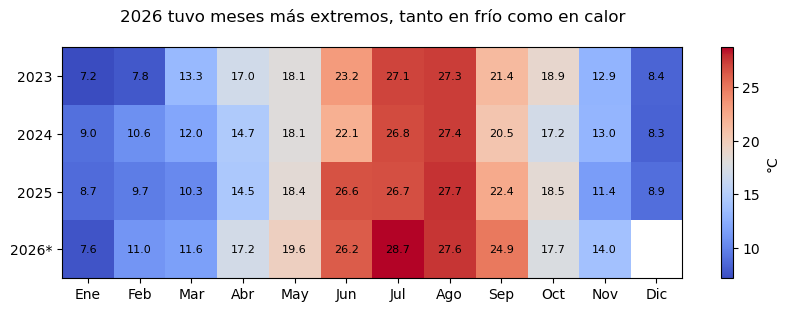

In [20]:
temp_mes = dias.groupby(["año", "mes"])["t_med"].mean().unstack(level="mes")

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(temp_mes, cmap="coolwarm", aspect="auto")

ax.set_xticks(range(12))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_yticks(range(len(temp_mes.index)))
ax.set_yticklabels([f"{a}*" if a == 2026 else a for a in temp_mes.index])

# Escribir el valor dentro de cada celda
for i in range(temp_mes.shape[0]):
    for j in range(temp_mes.shape[1]):
        valor = temp_mes.iloc[i, j]
        if pd.notna(valor):
            ax.text(j, i, f"{valor:.1f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="°C")
ax.set_title("2026 tuvo meses más extremos, tanto en frío como en calor\n")
plt.show()

El año 2026 tuvo meses más extremos, tanto en frío como en calor, lo cual ayuda a explicar por qué su demanda fue la más alta. Julio de 2026 fue el mes más caluroso de los cuatro años (28,7 °C) y coincide con el máximo de demanda (814,83 GWh). Septiembre de 2026 (24,9 °C) también fue mucho más caluroso que los demás septiembres, y enero de 2026 (7,6 °C), de los más fríos, fue el enero con más demanda (779 GWh).

# Parte B · SQL


**B1.** Saca los cinco días más calurosos (vista `temperatura_nacional`) junto con su demanda. ¿Son también días de mucha demanda? Explica por qué en una o dos frases.

In [21]:
#Se plantea la consulta SQL. Se sabe que para los días de la semana domingo=0 y sábado=6
sql_1 = """
       SELECT d.fecha,
       strftime('%w', d.fecha) AS dia_semana,
       d.demanda_gwh,
       t.t_med
       FROM demanda AS d
       JOIN temperatura_nacional AS t ON d.fecha = t.fecha
       ORDER BY t.t_med DESC
       LIMIT 5;
       """

#Se construye el df
df_Tmax = pd.read_sql(sql_1, conexion)

print("Demanda de los 5 días más calurosos\n")

df_Tmax.round(2)

Demanda de los 5 días más calurosos



,fecha,dia_semana,demanda_gwh,t_med
0,2025-08-16,6,712.44,31.81
1,2025-08-17,0,698.79,31.79
2,2023-08-23,3,805.11,31.61
3,2025-08-11,1,770.15,31.49
4,2025-06-29,0,707.45,31.43


Solo en parte: los cinco días superan la demanda media de su tipo de día (laborable o descanso), lo cual sugiere que con el aumento de la temperatura se incrementa el consumo de energía eléctrica, por ejemplo, por un mayor uso de aire acondicionado. Sin embargo, solo uno (el miércoles 23/08/2023) superó los 800 GWh, ya que tres de los cinco días cayeron en fin de semana.

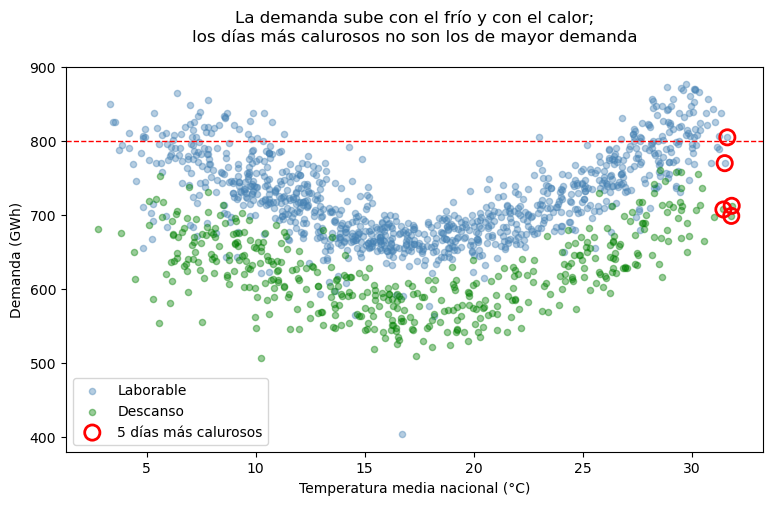

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))

# Todos los días, coloreados según sean laborables o de descanso
lab = dias[dias["descanso"] == False]
desc = dias[dias["descanso"] == True]
ax.scatter(lab["t_med"], lab["demanda_gwh"], s=20, alpha=0.4, color="steelblue", label="Laborable")
ax.scatter(desc["t_med"], desc["demanda_gwh"], s=20, alpha=0.4, color="green", label="Descanso")

# Los 5 días más calurosos, destacados
ax.scatter(df_Tmax["t_med"], df_Tmax["demanda_gwh"], s=120, facecolors="none",
           edgecolors="red", linewidths=2, label="5 días más calurosos")

ax.axhline(800, color="red", linestyle="--", linewidth=1)
ax.set_title("La demanda sube con el frío y con el calor;\nlos días más calurosos no son los de mayor demanda\n")
ax.set_xlabel("Temperatura media nacional (°C)")
ax.set_ylabel("Demanda (GWh)")
ax.legend()
plt.show()

Los días de descanso (verde) están siempre por debajo de los laborables (azul), a cualquier temperatura, y la demanda sube tanto con el frío como con el calor. Los cinco días más calurosos no son los de mayor demanda: los picos corresponden a días laborables de entre 28 y 30 °C. El punto aislado de 403 GWh corresponde al apagón del 28/04/2025.

**B2.** Para cada año, calcula la generación solar fotovoltaica en TWh y qué porcentaje supone de toda la generación del año.

In [23]:
#Se exploran los diferentes tipos de tecnología empleada en la generación de energía: 
sql_2 = """
    SELECT DISTINCT tecnologia 
    FROM generacion;
    """

#Se construye el df
df_Tec = pd.read_sql(sql_2, conexion)

print("Las tecnologías empleadas en la generación de energía son: \n")

df_Tec

Las tecnologías empleadas en la generación de energía son: 



,tecnologia
0,Hidráulica
1,Nuclear
2,Carbón
3,Motores diésel
4,Turbina de gas
5,Turbina de vapor
6,Ciclo combinado
7,Hidroeólica
8,Eólica
9,Solar fotovoltaica


In [24]:
# Se calcula la generación total de energía solar fotovoltaica en TWh por año: 
sql_Fotovoltaica_año = """
                       SELECT strftime('%Y', fecha) AS año,
                       SUM(gwh) / 1000.0 AS fotovoltaica_twh
                       FROM generacion
                       WHERE tecnologia = 'Solar fotovoltaica'
                       GROUP BY año;
                       """
#Se construye el df
df_Fotovoltaica_año = pd.read_sql(sql_Fotovoltaica_año, conexion)

print("Generación anual de energía solar fotovoltaica en TWh: \n")

df_Fotovoltaica_año.round(2)

Generación anual de energía solar fotovoltaica en TWh: 



,año,fotovoltaica_twh
0,2023,37.45
1,2024,44.60
2,2025,50.29
3,2026,55.41


In [25]:
# Se calcula la generación total de energía en TWh por año: 
sql_energia_anual = """
                       SELECT strftime('%Y', fecha) AS año,
                       SUM(gwh) / 1000.0 AS total_twh
                       FROM generacion
                       GROUP BY año;
                       """
#Se construye el df
df_energia_anual = pd.read_sql(sql_energia_anual, conexion)

print("Generación anual de energía en TWh: \n")

df_energia_anual.round(2)

Generación anual de energía en TWh: 



,año,total_twh
0,2023,263.61
1,2024,262.43
2,2025,272.41
3,2026,247.37


In [26]:
#Se unen ambas tablas para generar una nueva donde se calcula el porcentaje:
resultado = df_Fotovoltaica_año.merge(df_energia_anual, on = "año")
resultado["porcentaje"] = resultado["fotovoltaica_twh"] / resultado["total_twh"] * 100
resultado.round(2)

,año,fotovoltaica_twh,total_twh,porcentaje
0,2023,37.45,263.61,14.21
1,2024,44.60,262.43,16.99
2,2025,50.29,272.41,18.46
3,2026,55.41,247.37,22.40


La generación solar fotovoltaica pasó de 37,45 TWh (14,2 %) en 2023 a 50,29 TWh (18,5 %) en 2025, con una tendencia ascendente. En 2026 ya suma 55,41 TWh (22,4 %), aunque el año no está completo; el porcentaje probablemente esté sobreestimado, porque faltan noviembre y diciembre, que son meses de poca generación solar.

Se realiza la siguiente gráfica de barras para mostrar el resultado anterior.

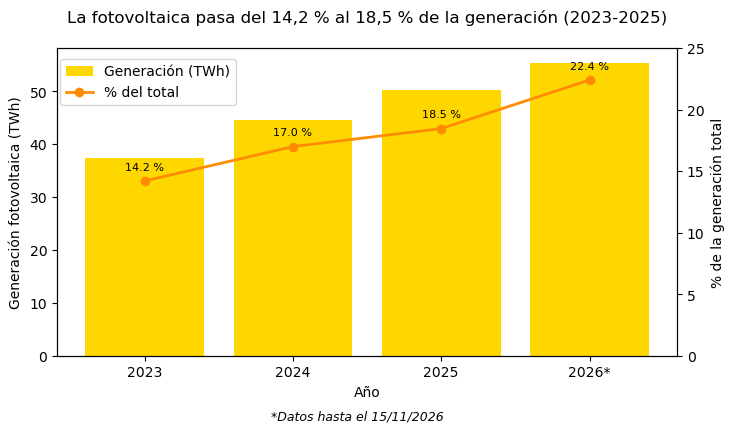

In [27]:
res = resultado.copy()
res["año"] = [f"{a}*" if a == "2026" else a for a in res["año"]]

fig, ax1 = plt.subplots(figsize=(8, 4))

# Barras: TWh (eje izquierdo)
ax1.bar(res["año"], res["fotovoltaica_twh"], color="gold", label="Generación (TWh)")
ax1.set_ylabel("Generación fotovoltaica (TWh)")
ax1.set_xlabel("Año")

# Línea: porcentaje (eje derecho)
ax2 = ax1.twinx()
ax2.plot(res["año"], res["porcentaje"], color="darkorange", marker="o", linewidth=2, label="% del total")
ax2.set_ylabel("% de la generación total")
ax2.set_ylim(0, 25)

# Valores encima
for i, v in enumerate(res["porcentaje"]):
    ax2.annotate(f"{v:.1f} %", (i, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)

ax1.set_title("La fotovoltaica pasa del 14,2 % al 18,5 % de la generación (2023-2025)\n")
fig.legend(loc="upper left", bbox_to_anchor=(0.12, 0.87))
plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026", ha="center", fontsize=9, style="italic")
plt.show()

La gráfica a continuación muestra la generación de energía eléctrica para la tecnología solar fotovoltaica. 

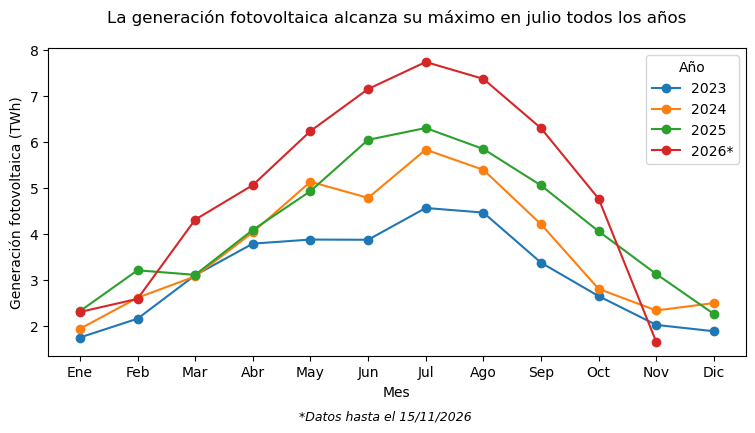

In [28]:
sql_fv_mes = """
SELECT strftime('%Y', fecha) AS año,
       CAST(strftime('%m', fecha) AS INTEGER) AS mes,
       SUM(gwh) / 1000.0 AS fv_twh
FROM generacion
WHERE tecnologia = 'Solar fotovoltaica'
GROUP BY año, mes;
"""
fv_mes = pd.read_sql(sql_fv_mes, conexion).pivot(index="mes", columns="año", values="fv_twh")
fv_mes.columns = [f"{a}*" if a == "2026" else a for a in fv_mes.columns]

ax = fv_mes.plot(marker="o", figsize=(9, 4))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("La generación fotovoltaica alcanza su máximo en julio todos los años\n")
ax.set_xlabel("Mes")
ax.set_ylabel("Generación fotovoltaica (TWh)")
ax.legend(title="Año")
plt.figtext(0.5, -0.05, "*Datos hasta el 15/11/2026", ha="center", fontsize=9, style="italic")
plt.show()

La generación fotovoltaica alcanza su máximo en julio todos los años y su mínimo en invierno, porque en verano hay más horas de sol. Además, cada año queda por encima del anterior casi todos los meses. En noviembre, la línea de 2026 cae porque solo incluye la primera quincena; como noviembre y diciembre son meses de poca generación solar, esto explica que el porcentaje de 2026 salga más alto.

**B3.** ¿Cuántos días de lluvia (1 mm o más) ha tenido cada ciudad? Ordena de más a menos.

In [29]:
# Consulta SQL
sql_lluvia_1mm = """
    SELECT ciudad, COUNT(*) AS dias_lluvia
    FROM tiempo
    WHERE lluvia_mm >=1
    GROUP BY ciudad
    ORDER BY dias_lluvia DESC;
    """
#Se construye el df
df_lluvia_mm = pd.read_sql(sql_lluvia_1mm, conexion)

print("Días con precipitación mayor o igual a 1mm por ciudad: \n")

df_lluvia_mm  


Días con precipitación mayor o igual a 1mm por ciudad: 



,ciudad,dias_lluvia
0,Bilbao,611
1,Barcelona,350
2,Madrid,305
3,Zaragoza,269
4,Sevilla,239
5,Valencia,218


En un periodo de casi 4 años, la ciudad con más días con precipitaciones mayores o iguales a 1mm es Bilbao con 611 días, seguida por Barcelona y Madrid con 350 y 305 días, respectivamente. La ciudad con menos días de lluvia ha sido Valencia con 218 días. 

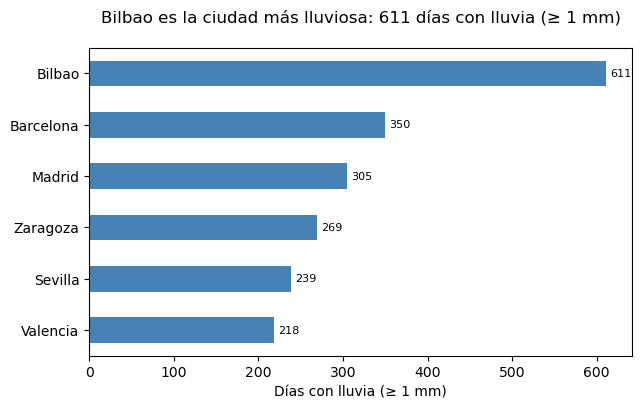

In [30]:
#Gráfico de barras

ax = df_lluvia_mm.sort_values("dias_lluvia").plot(
    kind="barh", x="ciudad", y="dias_lluvia", legend=False, color="steelblue", figsize=(7, 4))

for barras in ax.containers:
    ax.bar_label(barras, fontsize=8, padding=3)

ax.set_title("Bilbao es la ciudad más lluviosa: 611 días con lluvia (≥ 1 mm)\n")
ax.set_xlabel("Días con lluvia (≥ 1 mm)")
ax.set_ylabel("")
plt.show()

**Reto (opcional).** Con `LAG`, saca los tres días en que la demanda más subió respecto al día anterior. ¿Qué pasó en el primero?

In [31]:
# Se plantea la consulta con lag
sql_reto = """
 SELECT fecha,
       demanda_gwh,
       demanda_anterior,
       demanda_gwh - demanda_anterior AS subida
 FROM (
    SELECT fecha,
           demanda_gwh,
           LAG(demanda_gwh) OVER (ORDER BY fecha) AS demanda_anterior
    FROM demanda
 )
 ORDER BY subida DESC
 LIMIT 3;
 """
#Se construye el df
df_reto = pd.read_sql(sql_reto, conexion)

print("Los tres días en los que la demanda más subió respecto al día anterior: \n")

df_reto.round(2)

Los tres días en los que la demanda más subió respecto al día anterior: 



,fecha,demanda_gwh,demanda_anterior,subida
0,2025-04-29,590.01,403.30,186.71
1,2026-01-07,849.73,681.28,168.44
2,2023-07-10,778.80,628.91,149.89


La mayor subida fue el 29/04/2025 (+186,71 GWh), pero no por un aumento real del consumo: el día anterior, 28 de abril, un gran apagón dejó sin electricidad a la península ibérica y la demanda cayó a 403 GWh. Las otras dos subidas también son rebotes tras un día de poca actividad: el 07/01/2026, tras el festivo de Reyes, y el 10/07/2023, un lunes después de un domingo.

In [32]:
# Comprobación con pandas: mismo cálculo con diff()
dias["subida"] = dias["demanda_gwh"].diff().round(2)
dias.nlargest(3, "subida")[["fecha", "demanda_gwh", "subida"]]

,fecha,demanda_gwh,subida
849,2025-04-29,590.008854,186.71
1102,2026-01-07,849.726680,168.44
190,2023-07-10,778.800770,149.89


Comprobación: el cálculo con diff() en pandas da los mismos tres días, y la fecha del apagón se contrastó con noticias.

# Parte C · Excel o Power BI

Esta parte no se hace en el cuaderno. Abre `excel/parte_c_paola_tron_escobosa.xlsx.

**C1.** Haz una tabla dinámica (en Power BI, una matriz) con la demanda media: los meses en filas y los años en columnas. Hay una celda que no se puede comparar con las demás. ¿Cuál es y por qué?

La celda que no se puede comparar es noviembre de 2026 (659,91 GWh). Los datos llegan hasta el 15/11/2026, así que su valor corresponde solo a la primera quincena del mes, y no al mes completo como en los años anteriores. Por otro lado, la celda de diciembre de 2026 está vacía porque aún no hay datos.

![Tabla dinámica de la demanda media por mes y año](../docs/img/c1_tabla_dinamica.png)

Comprobación: los valores de la tabla dinámica coinciden con los calculados en pandas en la A3 (máximo en julio de 2026, 814,83 GWh, y mínimo en abril de 2023, 610,56 GWh).

**C2.** Haz un gráfico de la generación de 2025 por tecnología (hoja `generacion`), ordenado de mayor a menor. Ponle un título que diga la conclusión, no solo el tema.

En 2025, la eólica fue la tecnología con mayor generación, con un 21,6 % del total. Cinco de las quince tecnologías generaron el 88,2 % de la electricidad; de ellas, tres son renovables (eólica, solar fotovoltaica e hidráulica) y aportan el 52,4 %, mientras que las dos no renovables (nuclear y ciclo combinado) aportan el 35,8 %. El resto de las tecnologías suma solo el 11,8 %. 

![Generación por tecnología en 2025](../docs/img/c2_generacion_2025_tabla_dinamica.png)

![Generación por tecnología en 2025](../docs/img/c2_generacion_2025_grafico.png)

# Parte D · Explica (obligatoria)

**D1.** Elige una decisión que hayas tenido que tomar en esta prueba y explica por qué la tomaste (4 a 6 líneas).

En la B1 tuve que decidir con qué comparar la demanda de los cinco días más calurosos para saber si era alta. Podía usar la media anual o la media de su mismo tipo de día (laborable o descanso). Elegí la segunda porque tres de los cinco días cayeron en fin de semana, y en la A2 se observó que en días de descanso la demanda es entre un 13,5 % y un 14,5 % menor que en laborables. Compararlos con la media anual hubiese introducido un error en la conclusión. Así pude ver que los cinco días superaban la media de su tipo de día, lo que sugiere que el calor aumenta la demanda.

**D2.** Cuenta tu resultado más interesante a alguien que no sabe de datos (3 líneas).

Las energías renovables han comenzado a ganar terreno frente a las convencionales. En 2025, más de la mitad de la electricidad se obtuvo del viento, el sol y el agua. Además, la energía del sol pasó de un 14 % a un 18 % del total en solo dos años.

**D3.** Di un límite de tu análisis, o algo que comprobarías si tuvieras más tiempo.

* **2026 no está completo** (datos hasta el 15/11/2026), lo cual afecta a la media anual, a noviembre en la C1 y al porcentaje solar de la B2. Podrían hacerse las comparaciones solo con los meses de enero a octubre de todos los años, o descartar 2026, dependiendo del análisis.
* **Cinco días no eran suficientes** para demostrar que la demanda aumenta con el calor. Por eso lo comprobé con los 1415 días (gráfico de dispersión) y con las medias mensuales, y se observa que la demanda sube tanto con el calor como con el frío. Aun así, no se puede separar el efecto de la temperatura de otros factores (día de la semana, vacaciones). Para ello sería interesante contar con la demanda por sector.

**D4.** Si has usado una IA, di para qué y cómo comprobaste que el resultado era correcto. Si no la has usado, dilo.

La IA se usó:

* Como asistente de código, para corregir la sintaxis y revisar errores.
* Como asistente de gráficos: se le pidió el código para graficar los resultados, que después adapté a mis datos.
* Como asistente de las consultas SQL.
* Para revisar la redacción de las conclusiones y preparar el README.

Para comprobar los resultados:

* Las consultas se ejecutaron primero en SQLite, para explorar las tablas, y después se trasladaron a Python.
* El reto con LAG se verificó con diff() en pandas y dio los mismos tres días.
* Los valores de la tabla dinámica de Excel coinciden con los calculados en pandas en la A3.
* Se plantearon consultas adicionales para verificar resultados de otros apartados (ver sql/consultas.sql).
* La fecha del apagón (28/04/2025) se contrastó con noticias en internet.
